In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Direct download from UCI (bank-full.csv uses ';' as separator)
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank.zip
!unzip -o -q bank.zip
!unzip -o -q bank-additional.zip 2>/dev/null; unzip -o -q bank.zip 2>/dev/null
!ls


bank-additional      bank.csv	    bank-names.txt  __MACOSX
bank-additional.zip  bank-full.csv  bank.zip	    sample_data


In [2]:
df = pd.read_csv("bank-full.csv", sep=";")
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()
print("Duplicates:", df.duplicated().sum())
print("Missing:", df.isna().sum().sum())
# 'unknown' is the real missing-value marker in this dataset
for c in df.select_dtypes("object"):
    n = (df[c] == "unknown").sum()
    if n: print(c, n, f"{n/len(df):.1%}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
Duplicates: 0
Missing: 0
job 288 0.6%
education 1857 4.1%
contact 13020 28.8%
poutcome 36959 81.7%


y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


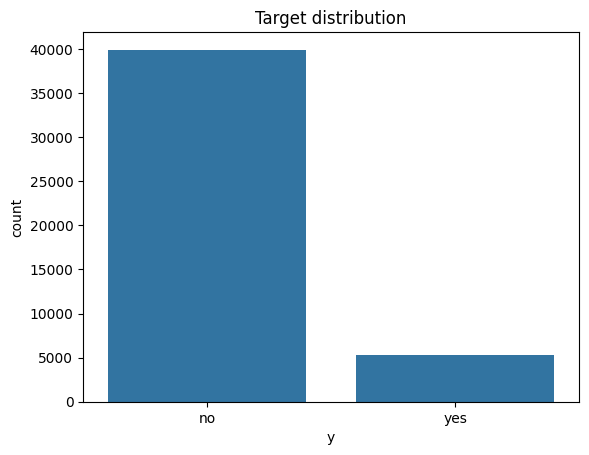

In [4]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))
sns.countplot(x="y", data=df); plt.title("Target distribution"); plt.show()

            count         mean          std     min    25%    50%     75%  \
age       45211.0    40.936210    10.618762    18.0   33.0   39.0    48.0   
balance   45211.0  1362.272058  3044.765829 -8019.0   72.0  448.0  1428.0   
day       45211.0    15.806419     8.322476     1.0    8.0   16.0    21.0   
duration  45211.0   258.163080   257.527812     0.0  103.0  180.0   319.0   
campaign  45211.0     2.763841     3.098021     1.0    1.0    2.0     3.0   
pdays     45211.0    40.197828   100.128746    -1.0   -1.0   -1.0    -1.0   
previous  45211.0     0.580323     2.303441     0.0    0.0    0.0     0.0   

               max  
age           95.0  
balance   102127.0  
day           31.0  
duration    4918.0  
campaign      63.0  
pdays        871.0  
previous     275.0  

pdays == -1: 36954
pdays     False  True 
poutcome              
False      8252      0
True          5  36954


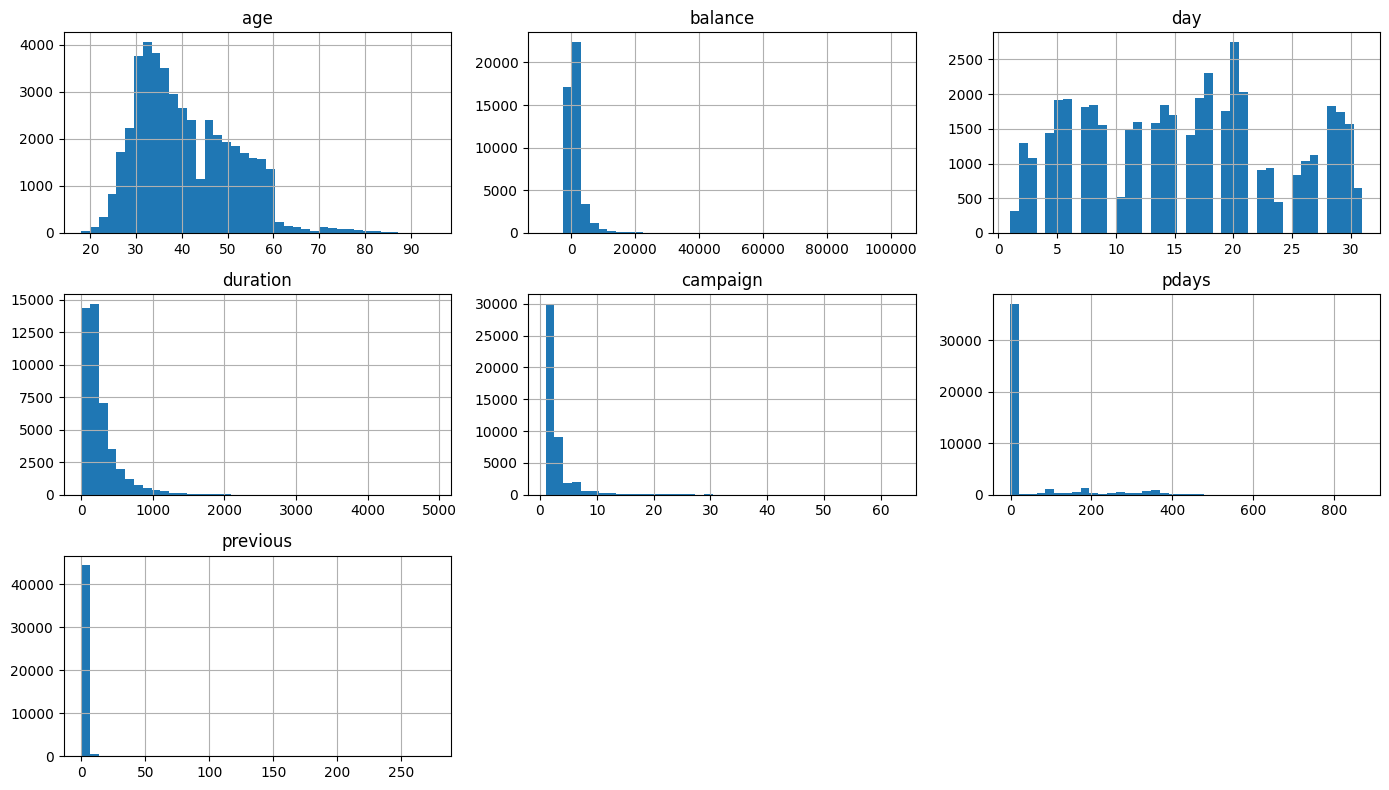

age: 487 outliers (1.1%)
balance: 4729 outliers (10.5%)
day: 0 outliers (0.0%)
duration: 3235 outliers (7.2%)
campaign: 3064 outliers (6.8%)
pdays: 8257 outliers (18.3%)
previous: 8257 outliers (18.3%)


In [5]:
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
print(df[num_cols].describe().T)

# Check the poutcome / pdays hypothesis
print("\npdays == -1:", (df["pdays"] == -1).sum())
print(pd.crosstab(df["poutcome"] == "unknown", df["pdays"] == -1))

# Histograms
df[num_cols].hist(bins=40, figsize=(14, 8))
plt.tight_layout(); plt.show()

# Outliers using the IQR rule
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c}: {n} outliers ({n/len(df):.1%})")

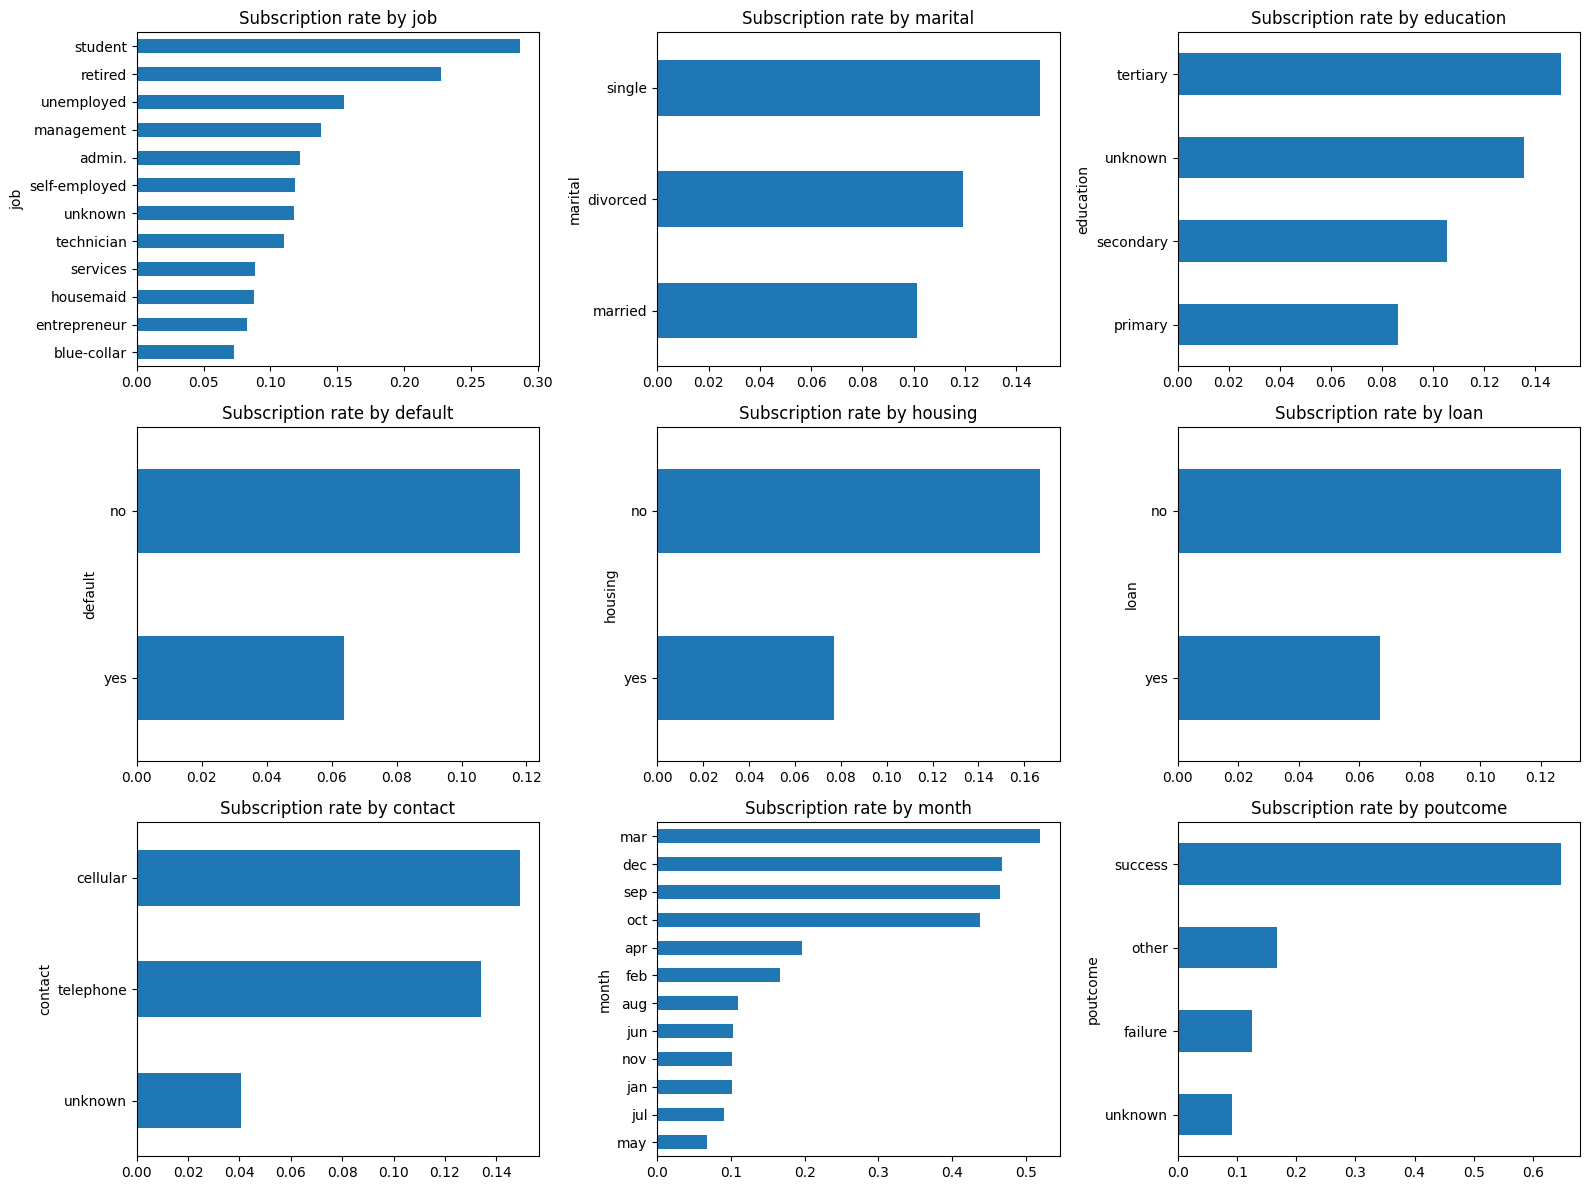

In [6]:
cat_cols = ["job", "marital", "education", "default", "housing",
            "loan", "contact", "month", "poutcome"]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    rate.plot.barh(ax=ax); ax.set_title(f"Subscription rate by {c}")
plt.tight_layout(); plt.show()

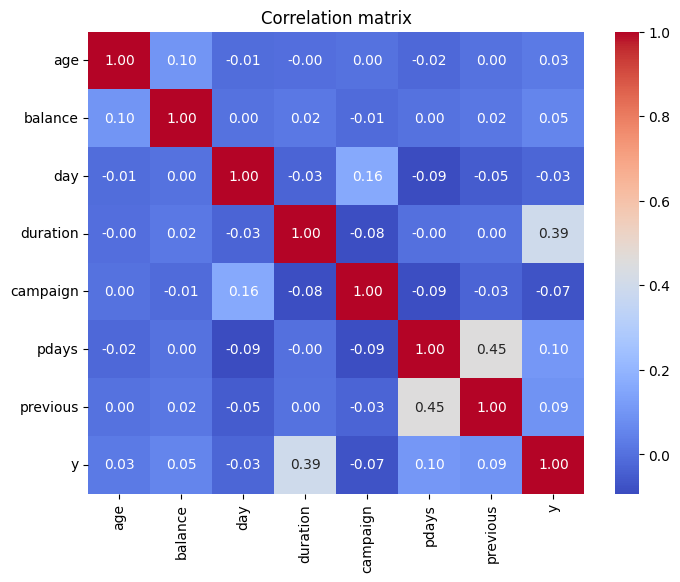

       count        mean         std  min    25%    50%    75%     max
y                                                                     
no   39922.0  221.182806  207.383237  0.0   95.0  164.0  279.0  4918.0
yes   5289.0  537.294574  392.525262  8.0  244.0  426.0  725.0  3881.0


In [7]:
df_num = df[num_cols].copy()
df_num["y"] = (df["y"] == "yes").astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

print(df.groupby("y")["duration"].describe())

In [8]:
# 1) Calls and rate per month (sample size matters)
m = df.groupby("month")["y"].agg(n="size", rate=lambda s: (s == "yes").mean())
print(m.sort_values("rate", ascending=False).round(3))

# 2) Age vs subscription rate (non-linear?)
age_bins = pd.cut(df["age"], [17, 25, 35, 45, 55, 65, 100])
print(df.groupby(age_bins, observed=True)["y"].agg(n="size", rate=lambda s: (s == "yes").mean()).round(3))

# 3) Correlation with the target
tmp = df[num_cols].copy()
tmp["y"] = (df["y"] == "yes").astype(int)
print(tmp.corr()["y"].sort_values(ascending=False).round(3))

# 4) Skewness of numeric features
print(df[num_cols].skew().round(2))

           n   rate
month              
mar      477  0.520
dec      214  0.467
sep      579  0.465
oct      738  0.438
apr     2932  0.197
feb     2649  0.166
aug     6247  0.110
jun     5341  0.102
nov     3970  0.102
jan     1403  0.101
jul     6895  0.091
may    13766  0.067
               n   rate
age                    
(17, 25]    1336  0.240
(25, 35]   15571  0.120
(35, 45]   13856  0.094
(45, 55]    9548  0.094
(55, 65]    4149  0.141
(65, 100]    751  0.426
y           1.000
duration    0.395
pdays       0.104
previous    0.093
balance     0.053
age         0.025
day        -0.028
campaign   -0.073
Name: y, dtype: float64
age          0.68
balance      8.36
day          0.09
duration     3.14
campaign     4.90
pdays        2.62
previous    41.85
dtype: float64


## EDA Findings and Modeling Decisions

| # | Finding | Evidence | Modeling decision |
|---|---|---|---|
| 1 | Strong class imbalance | `no` 88.3% vs `yes` 11.7% (about 7.5:1) | Stratified train/val/test split, class weights, and primary metric = F1 of the `yes` class (accuracy is misleading: a majority classifier gets ~88%) |
| 2 | No NaN values and no duplicates | 0 missing, 0 duplicate rows | No rows dropped |
| 3 | `unknown` is a real category, not random missingness | `job` 0.6%, `education` 4.1%, `contact` 28.8%, `poutcome` 81.7%; subscription rate for `contact=unknown` is ~4% vs ~15% for cellular | Keep `unknown` as its own category in one-hot encoding |
| 4 | `pdays = -1` is a sentinel, not a number | 36,954 rows have `pdays = -1`, and they match `poutcome = unknown` (36,954 of 36,959) | Add a `previously_contacted` flag; do not feed -1 as a real number of days |
| 5 | Heavy skew and long tails | skew: `previous` 41.85, `balance` 8.36, `campaign` 4.90, `pdays` 2.62; `balance` ranges from -8,019 to 102,127 | Keep rows (values are real); apply log1p/clipping fitted on train only, then scale |
| 6 | `duration` is the strongest numeric signal but is leakage | corr with target 0.395; mean 537s for `yes` vs 221s for `no`; known only after the call ends | Exclude `duration` from the main pipeline |
| 7 | Age has a non-linear (U-shaped) effect | rate: <=25 -> 24.0%, 35-55 -> ~9.4%, >65 -> 42.6%; linear corr with target only 0.025 | Keep `age` as a numeric feature; a linear baseline may miss this pattern, which is a case for a Neural Network |
| 8 | Month matters but sample sizes differ a lot | mar/dec/sep/oct: 44-52% but only 2,008 calls in total; may: 6.7% on 13,766 calls | Keep `month` as a categorical feature; report sample size when quoting rates |
| 9 | `poutcome = success` is a very strong signal | ~65% subscription rate | Keep `poutcome` one-hot encoded |
| 10 | Job and marital status are informative | student ~29%, retired ~23%, blue-collar ~7%; single > divorced > married | One-hot encode `job` and `marital` |
| 11 | `housing`, `loan`, `default` = `yes` lowers subscription rate | clear gaps in the bar charts | Binary encoding |
| 12 | `duration = 0` rows exist | minimum duration is 0 | Not a problem since `duration` is excluded; noted for completeness |